# Train the availability model (MLP)

This notebook trains the model for the question in `docs/project_proposal.pdf`: *"If I arrive at station S in `h` minutes (2 to 15), will there be at least one classic bike, one e-bike, and one free dock?"* It reads the table built by `build_dataset.ipynb` (`data/processed/training_table.parquet`).

**The model only answers the uncertain cases.** A label counts in the loss and in the scores only on rows where its count now is `<= 2` (its mask `m_*` is 1). Above that, the system answers "available" by rule, the same as the app.

### Decisions

| Choice | Decision | Why |
|---|---|---|
| Model | One MLP shared by all stations, plus a 16-number station embedding | Each row is a fixed set of features with only three time points (now, 10 and 30 min ago), so a GRU or 1-D CNN has no real sequence to use, and the table has no neighbour features for a graph network. The proposal lists the MLP first. |
| Layers | 3 × [Linear → BatchNorm → ReLU → Dropout 0.1], widths 256, 256, 128 | About 130k parameters: small next to 7.5M training rows, large enough to learn interactions such as count now × `h` × hour. |
| Outputs | 3 logits → 3 independent sigmoids | The labels are separate yes/no questions and any combination is possible, so no softmax. |
| Loss | Masked binary cross-entropy (BCE), averaged per label, then over the 3 labels | Only uncertain labels count. Averaging per label keeps the dock output (1.0M training rows) from being drowned out by e-bikes (6.9M). |
| No class weights | Plain BCE | Labels are 30–60% positive on masked-in rows, so the imbalance is mild. Reweighting would bias the probabilities, and the main score (Brier) punishes that. BCE already trains for calibrated probabilities. |
| Optimizer | AdamW, peak learning rate 2e-3, weight decay 1e-4, batch 4096, OneCycle schedule, early stopping on val loss | Robust defaults for a tabular MLP. Large batches are fine because rows are very redundant (3 horizons per anchor, anchors 10 minutes apart). |
| Main score | Brier score per label, on masked-in rows | The same score as the sanity baseline in the build notebook. Lower is better. |
| Baselines | App rule, lookup table, gradient-boosted trees | The app's count is today's answer. The proposal says to keep the network that best beats a gradient-boosted model. |

### Where this differs from the docs

1. **Loss weighting.** Section 10 of `docs/bikeshare_dataset_build_plan.md` pools all masked-in labels into one average. Here each label is averaged on its own first (see the table above).
2. **`renting_now` and `returning_now` are not used.** They are 1 on every row, so they carry no information and can't be standardized. The notebook stops if that changes.
3. **Unknown stations.** A few val/test stations never appear in training. They share an "unknown station" embedding, which is trained by giving 5% of training rows that embedding instead of their own.

### Setup and running

Use the `ebike` kernel (see `build_dataset.ipynb`). `torch` and `scikit-learn` are now in `requirements.txt`:

```bash
conda activate ebike
pip install -r requirements.txt
```

Use **Run All**. The full run took about 3.5 minutes on the RTX 500 Ada laptop GPU, with a peak of about 2.1 GB of GPU memory. Most of that is the gradient-boosted baseline (about 2.5 minutes). The MLP trains in about 30 seconds, because early stopping ends it after about 8 epochs. Outputs go to `models/`, which git ignores.

**The test split is not scored unless `RUN_TEST = True`.** Pick the model and settings on validation, then score the test split once.

## 0. Imports and configuration

Everything you may want to change is in this cell.

In [20]:
import copy
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_PATH = PROCESSED_DIR / "training_table.parquet"
STATION_LOOKUP_PATH = PROCESSED_DIR / "station_lookup.csv"
MODEL_DIR = PROJECT_ROOT / "models"

RUN_TEST = True           # score the test split. Leave False until the model and its settings are final.

# Must match build_dataset.ipynb
LOW_COUNT_K = 2
RANDOM_SEED = 1517
LOCAL_TZ = "America/Toronto"

# Model
EMBED_DIM = 16             # station embedding size
HIDDEN = [256, 256, 128]   # hidden layer widths
DROPOUT = 0.1
STATION_DROPOUT = 0.05     # share of training rows given the "unknown station" embedding

# Training
BATCH_SIZE = 4096
EPOCHS = 15                # upper limit; early stopping usually ends sooner
LR = 2e-3                  # peak learning rate of the OneCycle schedule
WEIGHT_DECAY = 1e-4
PATIENCE = 3               # stop after this many epochs without a better val loss
EVAL_BATCH = 65_536

# Baselines
LOOKUP_PRIOR = 50                # small lookup cells are shrunk toward their parent cell by this many pseudo-rows
GBM_MAX_TRAIN_ROWS = 3_000_000   # per label; a random subsample keeps the run time down
GBM_PARAMS = dict(learning_rate=0.1, max_iter=500, max_leaf_nodes=63, min_samples_leaf=200,
                  l2_regularization=1.0, early_stopping=True, n_iter_no_change=20)

# Station for the example query at the end
EXAMPLE_STATION_ID = 7000

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ON_GPU = DEVICE.type == "cuda"   # keep the train and val tensors on the GPU (about 1.7 GB)

rng = np.random.default_rng(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
MODEL_DIR.mkdir(exist_ok=True)

print("Table: ", TABLE_PATH)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("torch", torch.__version__)

Table:  /home/zweminhtetaung/mie1517_ebike_project/data/processed/training_table.parquet
Device: cuda NVIDIA RTX 500 Ada Generation Laptop GPU
torch 2.15.0+cu132


### Columns

Every input column is listed by name. Nothing is selected as "everything except the labels", so a new column in the table can't reach the model by accident.

`FORBIDDEN_INPUTS` holds the columns that must never be inputs: the answer (`label_ts`, `*_future`), the labels, the masks, and the IDs. The answer columns are not even loaded.

In [2]:
LABELS = ["classic", "ebike", "dock"]
NOW_COL = {"classic": "classic_now", "ebike": "ebike_now", "dock": "docks_now"}   # label -> its count at t
COUNT_TYPES = ["classic", "ebike", "docks"]
LAGS = ["tm10", "tm30"]

# Table columns the features are built from
INPUT_COLUMNS = (
    ["h"]
    + [f"{c}_{s}" for c in COUNT_TYPES for s in ["now"] + LAGS]
    + ["capacity", "lat", "lon", "hour_sin", "hour_cos", "is_weekend", "temp_c", "rel_humidity"]
)
EMBED_COLUMN = "station_idx"                        # used only through the embedding layer
UNUSED_INPUTS = ["renting_now", "returning_now"]    # constant 1 in the table; checked in Step 1
Y_COLUMNS = [f"y_{k}" for k in LABELS]
M_COLUMNS = [f"m_{k}" for k in LABELS]
ID_COLUMNS = ["station_id", "t", "t_local", "split", "h_target"]

ANSWER_COLUMNS = ["label_ts", "classic_future", "ebike_future", "docks_future"]
FORBIDDEN_INPUTS = set(ANSWER_COLUMNS + Y_COLUMNS + M_COLUMNS + ID_COLUMNS)
assert FORBIDDEN_INPUTS.isdisjoint(INPUT_COLUMNS + [EMBED_COLUMN]), "a forbidden column is listed as an input"
print(f"{len(INPUT_COLUMNS)} input columns + {EMBED_COLUMN}:", ", ".join(INPUT_COLUMNS))

18 input columns + station_idx: h, classic_now, classic_tm10, classic_tm30, ebike_now, ebike_tm10, ebike_tm30, docks_now, docks_tm10, docks_tm30, capacity, lat, lon, hour_sin, hour_cos, is_weekend, temp_c, rel_humidity


## 1. Load the table

Loads only the columns listed above. Then it checks that:

- the answer columns are not in memory,
- nothing is missing,
- the three splits don't overlap in time,
- `renting_now` and `returning_now` are still constant (if not, they should become inputs).

In [3]:
start = time.time()
LOAD_COLUMNS = ID_COLUMNS + [EMBED_COLUMN] + INPUT_COLUMNS + UNUSED_INPUTS + Y_COLUMNS + M_COLUMNS
df = pd.read_parquet(TABLE_PATH, columns=LOAD_COLUMNS)
assert not set(ANSWER_COLUMNS) & set(df.columns), "answer columns were loaded"
assert not df.isna().any(axis=None), "missing values in the table"

# t is an ISO UTC string with only a few thousand distinct values, so parse each one once
codes, uniques = pd.factorize(df["t"])
df["t"] = pd.DatetimeIndex(pd.to_datetime(uniques, format="%Y-%m-%dT%H:%M:%SZ", utc=True))[codes]

stations = pd.read_csv(STATION_LOOKUP_PATH)
N_STATIONS = len(stations)
UNKNOWN_STATION = N_STATIONS          # extra embedding row for stations never seen in training
assert df[EMBED_COLUMN].between(0, N_STATIONS - 1).all(), "station_idx outside station_lookup.csv"

SPLITS = ["train", "val", "test"]
split_idx = {s: np.flatnonzero(df["split"].to_numpy() == s) for s in SPLITS}
assert sum(len(i) for i in split_idx.values()) == len(df), "unknown split value"
t_range = {s: (df["t"].iloc[i].min(), df["t"].iloc[i].max()) for s, i in split_idx.items()}
assert t_range["train"][1] < t_range["val"][0] and t_range["val"][1] < t_range["test"][0], "splits overlap in time"

for col in UNUSED_INPUTS:
    assert df[col].iloc[split_idx["train"]].nunique() == 1, f"{col} is no longer constant: add it to the inputs"

overview = []
for s, i in split_idx.items():
    row = {"split": s, "rows": len(i),
           "first t (Toronto)": t_range[s][0].tz_convert(LOCAL_TZ).strftime("%Y-%m-%d %H:%M"),
           "last t (Toronto)": t_range[s][1].tz_convert(LOCAL_TZ).strftime("%Y-%m-%d %H:%M")}
    for k in LABELS:
        row[f"masked-in {k}"] = int(df[f"m_{k}"].to_numpy()[i].sum())
    overview.append(row)
display(pd.DataFrame(overview).set_index("split"))
N_ROWS = len(df)
print(f"{N_ROWS:,} rows, {N_STATIONS:,} stations, loaded in {time.time() - start:.0f} s")

,rows,first t (Toronto),last t (Toronto),masked-in classic,masked-in ebike,masked-in dock
split,,,,,,
train,7525845,2026-09-29 02:27,2026-10-18 23:57,3814256,6937178,1028334
val,2083617,2026-10-19 00:07,2026-10-23 23:57,1068040,1929731,285588
test,1747660,2026-10-24 00:07,2026-10-28 04:27,894074,1609180,252537


11,357,122 rows, 1,073 stations, loaded in 2 s


## 2. Features

All features use values at `t` only. The scaling statistics (mean and standard deviation) come from the **train split only**, so nothing about val or test leaks in.

| Features | Count | Transform |
|---|---|---|
| Counts now, 10 and 30 min ago (classic, e-bike, docks) | 9 | log(1 + x), then standardized |
| Trends: now − 10 min ago, now − 30 min ago | 6 | sign(x) · log(1 + abs(x)), then standardized. This squeezes the big jumps from rebalancing trucks |
| Count now is 0 / 1 / 2 / 3+, per type | 12 | One-hot. The count now decides most labels, so the model gets it directly |
| `h` | 1 | Standardized |
| `capacity` | 1 | log(1 + x), then standardized |
| `lat`, `lon`, `temp_c`, `rel_humidity` | 4 | Standardized |
| `hour_sin`, `hour_cos`, `is_weekend` | 3 | As is |
| `station_idx` | | 16-number embedding. Stations not in train use the unknown row |

The table shows each feature's train statistics and its scaled mean on val. A val mean far from 0 means that feature drifted: `temp_c`, for example, falls through October.

In [4]:
STANDARDIZED_PREFIXES = ("log_", "trend_")
STANDARDIZED_NAMES = {"h", "lat", "lon", "temp_c", "rel_humidity"}


def raw_features(frame: pd.DataFrame) -> dict[str, np.ndarray]:
    """Unscaled features in a fixed order. Reads only INPUT_COLUMNS."""
    f = {}
    for c in COUNT_TYPES:
        for s in ["now"] + LAGS:
            f[f"log_{c}_{s}"] = np.log1p(frame[f"{c}_{s}"].to_numpy(np.float32))
    for c in COUNT_TYPES:
        now = frame[f"{c}_now"].to_numpy(np.float32)
        for s in LAGS:
            d = now - frame[f"{c}_{s}"].to_numpy(np.float32)
            f[f"trend_{c}_{s}"] = np.sign(d) * np.log1p(np.abs(d))
    for c in COUNT_TYPES:
        now = frame[f"{c}_now"].to_numpy()
        for b in range(LOW_COUNT_K + 1):
            f[f"{c}_now_is_{b}"] = (now == b).astype(np.float32)
        f[f"{c}_now_is_{LOW_COUNT_K + 1}plus"] = (now > LOW_COUNT_K).astype(np.float32)
    f["h"] = frame["h"].to_numpy(np.float32)
    f["log_capacity"] = np.log1p(frame["capacity"].to_numpy(np.float32))
    for c in ["lat", "lon", "temp_c", "rel_humidity", "hour_sin", "hour_cos", "is_weekend"]:
        f[c] = frame[c].to_numpy(np.float32)
    return f


def is_standardized(name: str) -> bool:
    return name.startswith(STANDARDIZED_PREFIXES) or name in STANDARDIZED_NAMES


def fit_stats(frame: pd.DataFrame) -> dict[str, tuple[float, float]]:
    """Mean and std per feature, from the rows given (the train split). (0, 1) leaves a feature as is."""
    stats = {}
    for name, x in raw_features(frame).items():
        x64 = x.astype(np.float64)
        stats[name] = (float(x64.mean()), float(x64.std())) if is_standardized(name) else (0.0, 1.0)
    return stats


def make_matrix(frame: pd.DataFrame, stats: dict) -> np.ndarray:
    f = raw_features(frame)
    assert list(f) == list(stats), "feature order changed"
    X = np.empty((len(frame), len(f)), dtype=np.float32)
    for j, (name, x) in enumerate(f.items()):
        mean, std = stats[name]
        X[:, j] = (x - mean) / std
    return X


def station_index(frame: pd.DataFrame, train_stations: np.ndarray) -> np.ndarray:
    """Embedding row per row: the station's own if it was seen in training, else the unknown row."""
    s = frame[EMBED_COLUMN].to_numpy(np.int64)
    return np.where(np.isin(s, train_stations), s, UNKNOWN_STATION)

In [5]:
start = time.time()
frames = {s: df.iloc[split_idx[s]].reset_index(drop=True) for s in SPLITS}
del df

stats = fit_stats(frames["train"])
FEATURE_NAMES = list(stats)
assert all(std > 0 for _, std in stats.values()), "a feature is constant in train"
train_stations = np.unique(frames["train"][EMBED_COLUMN].to_numpy())

data = {}
for s in SPLITS:
    data[s] = {
        "X": make_matrix(frames[s], stats),
        "S": station_index(frames[s], train_stations),
        "Y": frames[s][Y_COLUMNS].to_numpy(np.float32),
        "M": frames[s][M_COLUMNS].to_numpy(np.float32),
    }
    assert np.isfinite(data[s]["X"]).all(), f"non-finite features in {s}"

print(f"{len(FEATURE_NAMES)} dense features, built in {time.time() - start:.0f} s")
for s in ["val", "test"]:
    unknown = data[s]["S"] == UNKNOWN_STATION
    n_st = frames[s].loc[unknown, "station_id"].nunique()
    print(f"{s}: {n_st} stations not seen in train, {unknown.sum():,} rows use the unknown embedding")

display(pd.DataFrame({
    "standardized": [is_standardized(n) for n in FEATURE_NAMES],
    "train mean (raw)": [stats[n][0] for n in FEATURE_NAMES],
    "train std (raw)": [stats[n][1] for n in FEATURE_NAMES],
    "val mean (scaled)": data["val"]["X"].mean(axis=0),
}, index=FEATURE_NAMES).round(3))

36 dense features, built in 8 s
val: 1 stations not seen in train, 1,008 rows use the unknown embedding
test: 2 stations not seen in train, 2,324 rows use the unknown embedding


,standardized,train mean (raw),train std (raw),val mean (scaled)
log_classic_now,True,1.332,1.074,-0.024
log_classic_tm10,True,1.333,1.074,-0.023
log_classic_tm30,True,1.334,1.074,-0.023
log_ebike_now,True,0.399,0.622,-0.028
log_ebike_tm10,True,0.400,0.623,-0.029
log_ebike_tm30,True,0.402,0.625,-0.030
log_docks_now,True,2.264,0.843,0.003
log_docks_tm10,True,2.264,0.843,0.003
log_docks_tm30,True,2.264,0.842,0.004
trend_classic_tm10,True,-0.002,0.328,-0.003


## 3. Baselines

All scores are per label, on that label's masked-in rows only.

1. **App rule:** p = 1 if the count now is at least 1, else 0. This is what a rider assumes from the app today.
2. **Lookup table:** the share of train rows that ended up available, for each combination of count now (0, 1, 2), whole minutes of `h`, and direction over the last 10 minutes (down, flat, up). Small cells are pulled toward their (count now, `h`) parent.
3. **Gradient-boosted trees** (scikit-learn `HistGradientBoostingClassifier`): one per label, on the same 36 features as the MLP. They get no station embedding, but trees can single out a station from `lat`, `lon` and `capacity`. Each is trained on up to 3M random train rows and stops early on val, as the MLP does.

`score()` gives the Brier score (the main metric), log loss, and AUC (how well a model ranks the rows that end up available above those that don't). The app gets no log loss: its 0/1 predictions make it infinite whenever it is wrong.

The app's val Brier must match the build notebook's sanity baseline. A mismatch means the table or the masks have changed.

In [6]:
def brier(y: np.ndarray, p: np.ndarray) -> float:
    return float(np.mean((p - y) ** 2))


def score(y: np.ndarray, p: np.ndarray, probabilistic: bool = True) -> dict:
    out = {"rows": len(y), "share available": float(y.mean()), "Brier": brier(y, p)}
    if probabilistic:
        q = np.clip(p, 1e-6, 1 - 1e-6)
        out["log loss"] = float(-np.mean(y * np.log(q) + (1 - y) * np.log(1 - q)))
    else:
        out["log loss"] = np.nan
    varies = 0 < y.mean() < 1 and np.unique(p).size > 1
    out["AUC"] = float(roc_auc_score(y, p)) if varies else np.nan
    return out


def masked(split: str, j: int) -> np.ndarray:
    """Rows of a split where label j is masked in."""
    return data[split]["M"][:, j] == 1


def predict_app(frame: pd.DataFrame) -> np.ndarray:
    return np.stack([(frame[NOW_COL[k]].to_numpy() >= 1).astype(np.float32) for k in LABELS], axis=1)


def lookup_keys(frame: pd.DataFrame, label: str) -> tuple[np.ndarray, np.ndarray]:
    """(count now, whole minutes of h) and that plus the 10-minute direction, as integer keys."""
    now = frame[NOW_COL[label]].to_numpy().astype(np.int64)
    h_min = np.clip(np.floor(frame["h"].to_numpy()), 2, 14).astype(np.int64)
    lag = frame[NOW_COL[label].replace("_now", "_tm10")].to_numpy().astype(np.int64)
    coarse = now * 100 + h_min
    return coarse, coarse * 3 + np.sign(now - lag) + 1


def fit_lookup(frame: pd.DataFrame) -> dict:
    tables = {}
    for k in LABELS:
        rows = frame[frame[f"m_{k}"] == 1]
        coarse, fine = lookup_keys(rows, k)
        y = rows[f"y_{k}"].to_numpy(np.float64)
        parent = pd.Series(y).groupby(coarse).mean()
        cells = pd.DataFrame({"y": y, "fine": fine, "coarse": coarse}).groupby("fine").agg(
            total=("y", "sum"), n=("y", "size"), coarse=("coarse", "first"))
        cells["p"] = (cells["total"] + LOOKUP_PRIOR * cells["coarse"].map(parent)) / (cells["n"] + LOOKUP_PRIOR)
        tables[k] = {"fine": cells["p"], "coarse": parent, "overall": float(y.mean())}
    return tables


def predict_lookup(frame: pd.DataFrame, tables: dict) -> np.ndarray:
    out = np.empty((len(frame), len(LABELS)), dtype=np.float32)
    for j, k in enumerate(LABELS):
        coarse, fine = lookup_keys(frame, k)
        p = pd.Series(fine).map(tables[k]["fine"])
        p = p.fillna(pd.Series(coarse).map(tables[k]["coarse"])).fillna(tables[k]["overall"])
        out[:, j] = p.to_numpy()
    return out


preds = {s: {} for s in SPLITS}      # split -> model name -> (rows, 3) probabilities
lookup_tables = fit_lookup(frames["train"])
for s in SPLITS:
    preds[s]["App"] = predict_app(frames[s])
    preds[s]["Lookup"] = predict_lookup(frames[s], lookup_tables)

# Must match the sanity baseline printed by build_dataset.ipynb for this table
BUILD_REFERENCE = {"rows": 11_357_116, "app_brier_val": {"classic": 0.0504, "ebike": 0.0458, "dock": 0.0863}}
app_val = {k: brier(data["val"]["Y"][masked("val", j), j], preds["val"]["App"][masked("val", j), j])
           for j, k in enumerate(LABELS)}
if N_ROWS == BUILD_REFERENCE["rows"]:
    for k, ref in BUILD_REFERENCE["app_brier_val"].items():
        assert abs(app_val[k] - ref) < 5e-5, f"app Brier for {k} is {app_val[k]:.4f}, the build notebook had {ref}"
    print("App baseline matches the build notebook.")
else:
    print("The table has been rebuilt since this check was written: update BUILD_REFERENCE.")

display(pd.DataFrame({
    name: {k: brier(data["val"]["Y"][masked("val", j), j], preds["val"][name][masked("val", j), j])
           for j, k in enumerate(LABELS)}
    for name in ["App", "Lookup"]
}).round(4).rename_axis("Val Brier"))

The table has been rebuilt since this check was written: update BUILD_REFERENCE.


,App,Lookup
Val Brier,,
classic,0.0504,0.0454
ebike,0.0458,0.0418
dock,0.0863,0.0741


### Gradient-boosted trees

This is the slowest cell. Each label gets its own model, which stops when its val loss hasn't improved for 20 trees.

In [7]:
start = time.time()
gbm_models = {}
for j, k in enumerate(LABELS):
    t0 = time.time()
    tr_rows = np.flatnonzero(masked("train", j))
    if len(tr_rows) > GBM_MAX_TRAIN_ROWS:
        tr_rows = np.sort(rng.choice(tr_rows, GBM_MAX_TRAIN_ROWS, replace=False))
    va_rows = np.flatnonzero(masked("val", j))
    gbm = HistGradientBoostingClassifier(**GBM_PARAMS, random_state=RANDOM_SEED)
    gbm.fit(data["train"]["X"][tr_rows], data["train"]["Y"][tr_rows, j],
            X_val=data["val"]["X"][va_rows], y_val=data["val"]["Y"][va_rows, j])
    gbm_models[k] = gbm
    print(f"{k}: {len(tr_rows):,} train rows, {gbm.n_iter_} trees, {time.time() - t0:.0f} s")


def predict_gbm(split: str) -> np.ndarray:
    """GBM probabilities on masked-in rows. Rows where a label is masked out stay NaN: the GBM never answers those."""
    out = np.full((len(data[split]["X"]), len(LABELS)), np.nan, dtype=np.float32)
    for j, k in enumerate(LABELS):
        rows = np.flatnonzero(masked(split, j))
        out[rows, j] = gbm_models[k].predict_proba(data[split]["X"][rows])[:, 1]
    return out


for s in ["val", "test"]:
    preds[s]["GBM"] = predict_gbm(s)
print(f"Done in {time.time() - start:.0f} s")

classic: 3,000,000 train rows, 281 trees, 52 s
ebike: 3,000,000 train rows, 331 trees, 58 s
dock: 1,028,334 train rows, 200 trees, 14 s
Done in 146 s


## 4. The model

One network for every station:

```
36 dense features ─┐
                   ├─ concat (52) → [Linear → BatchNorm → ReLU → Dropout] × 3 (256, 256, 128) → Linear → 3 logits
station embedding ─┘   (16)
```

The outputs are logits. `torch.sigmoid` turns them into the three probabilities (classic, e-bike, dock). The embedding has one row per station plus a last row for unknown stations. It starts small (std 0.1), so station identity doesn't dominate early training.

In [8]:
class AvailabilityMLP(nn.Module):
    """Shared MLP: dense features + station embedding -> 3 logits (classic, e-bike, dock)."""

    def __init__(self, n_features: int, n_stations: int, embed_dim: int = EMBED_DIM,
                 hidden: list[int] = HIDDEN, dropout: float = DROPOUT):
        super().__init__()
        self.station_embedding = nn.Embedding(n_stations + 1, embed_dim)   # last row: unknown station
        nn.init.normal_(self.station_embedding.weight, std=0.1)
        layers, width = [], n_features + embed_dim
        for w in hidden:
            layers += [nn.Linear(width, w), nn.BatchNorm1d(w), nn.ReLU(), nn.Dropout(dropout)]
            width = w
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(width, len(LABELS))

    def forward(self, x: torch.Tensor, station: torch.Tensor) -> torch.Tensor:
        z = torch.cat([x, self.station_embedding(station)], dim=1)
        return self.head(self.body(z))


# Shape test on random input, including the unknown station
check_model = AvailabilityMLP(len(FEATURE_NAMES), N_STATIONS)
out = check_model(torch.randn(8, len(FEATURE_NAMES)), torch.tensor([0, 1, 2, 3, 4, 5, 6, UNKNOWN_STATION]))
assert out.shape == (8, len(LABELS)) and torch.isfinite(out).all()
print(check_model)
print(f"{sum(p.numel() for p in check_model.parameters()):,} parameters")
del check_model

AvailabilityMLP(
  (station_embedding): Embedding(1074, 16)
  (body): Sequential(
    (0): Linear(in_features=52, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.1, inplace=False)
  )
  (head): Linear(in_features=128, out_features=3, bias=True)
)
131,107 parameters


## 5. The masked loss

For each label k, the mean BCE over the rows where `m_k = 1`. The loss is the mean of those three numbers, over the labels that have any masked-in rows in the batch. A label with `m_k = 0` on a row adds nothing to the loss or its gradient.

The test checks the value by hand, checks that changing a masked-out label changes nothing, and checks that a label with no masked-in rows is skipped instead of producing NaN.

In [9]:
def masked_bce(logits: torch.Tensor, y: torch.Tensor, m: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Returns (loss, per-label mean BCE). logits, y and m have shape (rows, 3)."""
    bce = F.binary_cross_entropy_with_logits(logits, y, reduction="none")
    n = m.sum(dim=0)
    per_label = (bce * m).sum(dim=0) / n.clamp(min=1)
    present = (n > 0).float()
    loss = (per_label * present).sum() / present.sum().clamp(min=1)
    return loss, per_label


g = torch.Generator().manual_seed(0)
logits = torch.randn(6, 3, generator=g)
y = torch.randint(0, 2, (6, 3), generator=g).float()
m = torch.tensor([[1, 0, 1], [1, 1, 0], [0, 1, 0], [1, 0, 0], [0, 1, 0], [1, 1, 1]]).float()
loss, per_label = masked_bce(logits, y, m)

by_hand = torch.stack([
    F.binary_cross_entropy_with_logits(logits[m[:, j] == 1, j], y[m[:, j] == 1, j]) for j in range(3)])
assert torch.allclose(per_label, by_hand) and torch.allclose(loss, by_hand.mean())

flipped = torch.where(m == 0, 1 - y, y)              # change only the masked-out labels
assert torch.allclose(masked_bce(logits, flipped, m)[0], loss)

no_dock = m.clone()
no_dock[:, 2] = 0                                     # a batch with no masked-in dock rows
loss_2, per_label_2 = masked_bce(logits, y, no_dock)
assert torch.isfinite(loss_2) and torch.allclose(loss_2, per_label_2[:2].mean())
print("Masked loss tests passed.")

Masked loss tests passed.


## 6. Train

- The train and val tensors sit on the GPU, and each epoch draws batches from a fresh random order of the rows. That is faster than a `DataLoader`.
- **Station dropout:** each training row has a 5% chance of using the unknown-station embedding, so that row learns an "average station".
- **OneCycle:** the learning rate warms up over the first 10% of steps to 2e-3, then decays smoothly toward 0.
- After each epoch, the val loss decides which model is kept. Training stops after `PATIENCE` epochs without improvement.
- The train loss is measured with dropout on, so it can sit a little above the val loss.

GPU results vary very slightly from run to run, even with a fixed seed.

In [10]:
def to_tensors(split: str, device: torch.device) -> dict[str, torch.Tensor]:
    # np.require copies read-only arrays (pandas returns some), which torch.from_numpy warns about
    return {k: torch.from_numpy(np.require(v, requirements="W")).to(device) for k, v in data[split].items()}


@torch.no_grad()
def predict_logits(model: nn.Module, X: torch.Tensor, S: torch.Tensor, batch: int = EVAL_BATCH) -> torch.Tensor:
    model.eval()
    return torch.cat([model(X[i:i + batch].to(DEVICE), S[i:i + batch].to(DEVICE))
                      for i in range(0, len(X), batch)])


@torch.no_grad()
def evaluate(model: nn.Module, t: dict[str, torch.Tensor]) -> dict:
    logits = predict_logits(model, t["X"], t["S"])
    y, m = t["Y"].to(DEVICE), t["M"].to(DEVICE)
    loss, per_label = masked_bce(logits, y, m)
    p = torch.sigmoid(logits)
    brier_k = ((p - y) ** 2 * m).sum(dim=0) / m.sum(dim=0).clamp(min=1)
    return {"loss": loss.item(), "per_label": per_label.cpu().numpy(), "brier": brier_k.cpu().numpy()}


data_device = DEVICE if DATA_ON_GPU else torch.device("cpu")
tensors = {s: to_tensors(s, data_device) for s in ["train", "val"]}
print(f"Train and val tensors on {data_device}")

Train and val tensors on cuda


In [11]:
torch.manual_seed(RANDOM_SEED)
model = AvailabilityMLP(len(FEATURE_NAMES), N_STATIONS).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
train = tensors["train"]
n_train = len(train["X"])
steps_per_epoch = n_train // BATCH_SIZE
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=EPOCHS * steps_per_epoch, pct_start=0.1)
if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

history, best_loss, best_state, best_epoch, epochs_without_gain = [], float("inf"), None, 0, 0
train_start = time.time()
print(f"{n_train:,} train rows, {steps_per_epoch:,} steps per epoch")
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    order = torch.randperm(n_train, device=data_device)
    loss_sum = torch.zeros(len(LABELS), device=DEVICE)
    mask_sum = torch.zeros(len(LABELS), device=DEVICE)
    for step in range(steps_per_epoch):
        idx = order[step * BATCH_SIZE:(step + 1) * BATCH_SIZE]
        xb, sb, yb, mb = (train[k][idx].to(DEVICE, non_blocking=True) for k in ["X", "S", "Y", "M"])
        if STATION_DROPOUT > 0:
            sb = torch.where(torch.rand(sb.shape, device=DEVICE) < STATION_DROPOUT, UNKNOWN_STATION, sb)
        loss, per_label = masked_bce(model(xb, sb), yb, mb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        scheduler.step()
        n = mb.sum(dim=0)
        loss_sum += per_label.detach() * n
        mask_sum += n

    train_per_label = (loss_sum / mask_sum.clamp(min=1)).cpu().numpy()
    val = evaluate(model, tensors["val"])
    record = {"epoch": epoch, "lr_end": scheduler.get_last_lr()[0],
              "train_loss": float(train_per_label.mean()), "val_loss": val["loss"]}
    for j, k in enumerate(LABELS):
        record[f"train_loss_{k}"] = float(train_per_label[j])
        record[f"val_loss_{k}"] = float(val["per_label"][j])
        record[f"val_brier_{k}"] = float(val["brier"][j])
    record["seconds"] = time.time() - t0
    history.append(record)

    improved = val["loss"] < best_loss - 1e-5
    if improved:
        best_loss, best_epoch, epochs_without_gain = val["loss"], epoch, 0
        best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
    else:
        epochs_without_gain += 1
    briers = "  ".join(f"{k} {val['brier'][j]:.4f}" for j, k in enumerate(LABELS))
    print(f"epoch {epoch:2d}  train {record['train_loss']:.4f}  val {val['loss']:.4f}  "
          f"| val Brier {briers}  | {record['seconds']:.0f} s{'  best' if improved else ''}")
    if epochs_without_gain >= PATIENCE:
        print(f"No improvement for {PATIENCE} epochs, stopping.")
        break

model.load_state_dict(best_state)
history_df = pd.DataFrame(history)
print(f"\nBest epoch {best_epoch} (val loss {best_loss:.4f}), trained in {time.time() - train_start:.0f} s")
if DEVICE.type == "cuda":
    print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

7,525,845 train rows, 1,837 steps per epoch
epoch  1  train 0.2021  val 0.1742  | val Brier classic 0.0409  ebike 0.0386  dock 0.0679  | 5 s  best
epoch  2  train 0.1722  val 0.1717  | val Brier classic 0.0402  ebike 0.0382  dock 0.0672  | 9 s  best
epoch  3  train 0.1697  val 0.1704  | val Brier classic 0.0402  ebike 0.0380  dock 0.0669  | 19 s  best
epoch  4  train 0.1680  val 0.1712  | val Brier classic 0.0400  ebike 0.0379  dock 0.0678  | 19 s
epoch  5  train 0.1669  val 0.1700  | val Brier classic 0.0399  ebike 0.0379  dock 0.0670  | 4 s  best
epoch  6  train 0.1660  val 0.1697  | val Brier classic 0.0398  ebike 0.0379  dock 0.0667  | 4 s  best
epoch  7  train 0.1652  val 0.1695  | val Brier classic 0.0398  ebike 0.0378  dock 0.0666  | 4 s  best
epoch  8  train 0.1644  val 0.1698  | val Brier classic 0.0398  ebike 0.0378  dock 0.0669  | 4 s
epoch  9  train 0.1636  val 0.1697  | val Brier classic 0.0398  ebike 0.0378  dock 0.0667  | 4 s
epoch 10  train 0.1629  val 0.1704  | val Bri

## 7. Training curves

The left chart shows the loss. The three small charts show the val Brier per label against the three baselines (horizontal lines). The MLP is worth keeping only if its line ends below the GBM line.

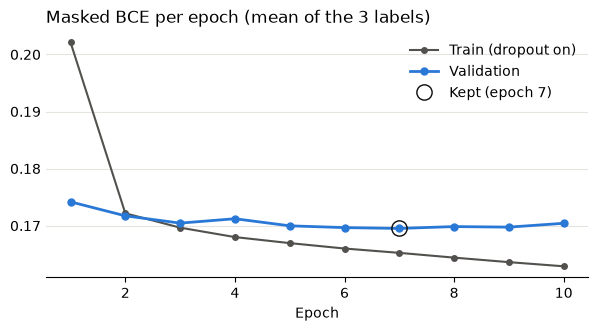

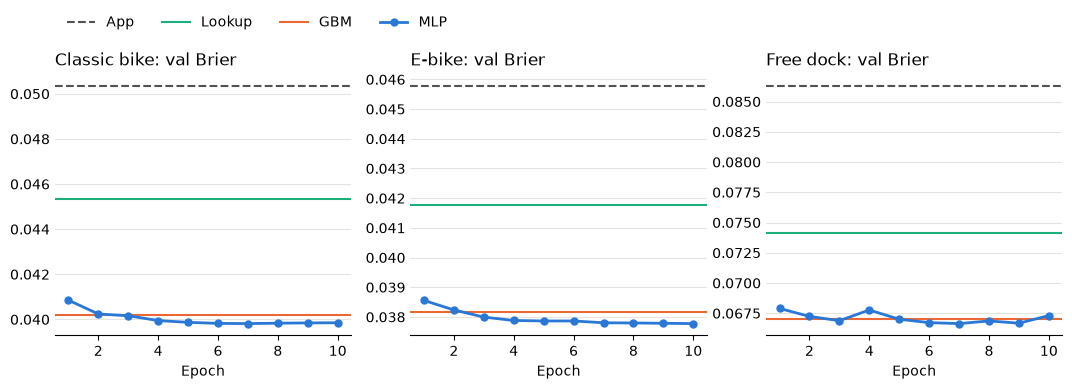

In [12]:
COLORS = {"MLP": "#2a78d6", "GBM": "#eb6834", "Lookup": "#1baf7a"}   # fixed order from a CVD-checked palette
REFERENCE = "#52514e"     # app rule, train curve, other reference lines
GRID = "#e5e4df"
INK = "#0b0b0b"
TITLE = {"classic": "Classic bike", "ebike": "E-bike", "dock": "Free dock"}


def tidy(ax: plt.Axes) -> None:
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)


fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(history_df["epoch"], history_df["train_loss"], color=REFERENCE, linewidth=1.5, marker="o", markersize=4,
        label="Train (dropout on)")
ax.plot(history_df["epoch"], history_df["val_loss"], color=COLORS["MLP"], linewidth=2, marker="o", markersize=5,
        label="Validation")
ax.plot([best_epoch], [best_loss], marker="o", markersize=11, markerfacecolor="none", markeredgecolor=INK,
        linestyle="none", label=f"Kept (epoch {best_epoch})")
ax.set_title("Masked BCE per epoch (mean of the 3 labels)", loc="left")
ax.set_xlabel("Epoch")
tidy(ax)
ax.legend(frameon=False)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for j, (ax, k) in enumerate(zip(axes, LABELS)):
    keep = masked("val", j)
    y = data["val"]["Y"][keep, j]
    ax.axhline(brier(y, preds["val"]["App"][keep, j]), color=REFERENCE, linestyle="--", linewidth=1.5, label="App")
    ax.axhline(brier(y, preds["val"]["Lookup"][keep, j]), color=COLORS["Lookup"], linewidth=1.5, label="Lookup")
    ax.axhline(brier(y, preds["val"]["GBM"][keep, j]), color=COLORS["GBM"], linewidth=1.5, label="GBM")
    ax.plot(history_df["epoch"], history_df[f"val_brier_{k}"], color=COLORS["MLP"], linewidth=2,
            marker="o", markersize=5, label="MLP")
    ax.set_title(f"{TITLE[k]}: val Brier", loc="left")
    ax.set_xlabel("Epoch")
    tidy(ax)
axes[0].legend(frameon=False, ncols=4, loc="lower left", bbox_to_anchor=(0, 1.12))
plt.show()

## 8. Validation results

### Main table

Per label, on masked-in val rows. **Brier skill vs app** is the share of the app's Brier error that a model removes (0 = no better than the app, 1 = perfect).

Val was also used for early stopping (MLP and GBM), so these numbers are slightly optimistic. The test split gives the honest number.

In [13]:
MODELS = ["App", "Lookup", "GBM", "MLP"]
preds["val"]["MLP"] = torch.sigmoid(predict_logits(model, tensors["val"]["X"], tensors["val"]["S"])).cpu().numpy()


def results_table(split: str) -> pd.DataFrame:
    Y, M = data[split]["Y"], data[split]["M"]
    rows = []
    for j, k in enumerate(LABELS):
        keep = M[:, j] == 1
        app_brier = brier(Y[keep, j], preds[split]["App"][keep, j])
        for name in MODELS:
            r = score(Y[keep, j], preds[split][name][keep, j], probabilistic=name != "App")
            r["Brier skill vs app"] = 1 - r["Brier"] / app_brier
            rows.append({"label": k, "model": name, **r})
    return pd.DataFrame(rows).set_index(["label", "model"])


val_results = results_table("val")
display(val_results.round(4))
display(val_results["Brier"].unstack("model")[MODELS].round(4).rename_axis("Val Brier"))

for k in LABELS:
    if val_results.loc[(k, "MLP"), "Brier"] < 0.25 * val_results.loc[(k, "App"), "Brier"]:
        print(f"WARNING: the MLP's {k} Brier is under a quarter of the app's. Check for leakage before trusting it.")

rows  share available   Brier  log loss     AUC  Brier skill vs app
label   model                                                                         
classic App     1068040           0.4488  0.0504       NaN  0.9489              0.0000
        Lookup  1068040           0.4488  0.0454    0.1815  0.9686              0.0994
        GBM     1068040           0.4488  0.0402    0.1447  0.9859              0.2022
        MLP     1068040           0.4488  0.0398    0.1428  0.9863              0.2094
ebike   App     1929731           0.3125  0.0458       NaN  0.9466              0.0000
        Lookup  1929731           0.3125  0.0418    0.1708  0.9634              0.0882
        GBM     1929731           0.3125  0.0382    0.1417  0.9828              0.1668
        MLP     1929731           0.3125  0.0378    0.1396  0.9836              0.1744
dock    App      285588           0.6036  0.0863       NaN  0.9107              0.0000
        Lookup   285588           0.6036  0.0741    0.2658  0.9464              0.1416
        GBM      285588           0.6036  0.0671    0.2285  0.9660              0.2231
        MLP      285588           0.6036  0.0666    0.2261  0.9668              0.2279

model,App,Lookup,GBM,MLP
Val Brier,,,,
classic,0.0504,0.0454,0.0402,0.0398
dock,0.0863,0.0741,0.0671,0.0666
ebike,0.0458,0.0418,0.0382,0.0378


### By count now and by horizon

The count now (0, 1, 2) decides most of the answer, so the overall AUC mostly measures that. **AUC within a group** shows whether a model ranks rows correctly *beyond* the count: for example, which of the stations showing one e-bike will still have it. The app's predictions don't vary within a group, so it gets no AUC there.

In [14]:
H_BUCKETS = ["2-5 min", "5-8 min", "8-11 min", "11-15 min"]


def group_count_now(frame: pd.DataFrame, k: str) -> np.ndarray:
    return frame[NOW_COL[k]].to_numpy()


def group_h(frame: pd.DataFrame, k: str) -> np.ndarray:
    return np.array(H_BUCKETS)[np.digitize(frame["h"].to_numpy(), [5, 8, 11])]


def breakdown(split: str, group_fn, group_name: str, order=None) -> pd.DataFrame:
    Y, M = data[split]["Y"], data[split]["M"]
    rows = []
    for j, k in enumerate(LABELS):
        keep = M[:, j] == 1
        groups, y = group_fn(frames[split], k)[keep], Y[keep, j]
        for value in (order if order is not None else np.unique(groups)):
            sel = groups == value
            r = {"label": k, group_name: value, "rows": int(sel.sum()), "share available": float(y[sel].mean())}
            for name in MODELS:
                r[f"Brier {name}"] = brier(y[sel], preds[split][name][keep, j][sel])
            for name in MODELS[1:]:
                r[f"AUC {name}"] = score(y[sel], preds[split][name][keep, j][sel])["AUC"]
            rows.append(r)
    return pd.DataFrame(rows).set_index(["label", group_name])


display(breakdown("val", group_count_now, "count now").round(4))
display(breakdown("val", group_h, "h", order=H_BUCKETS).round(4))

rows  share available  Brier App  Brier Lookup  Brier GBM  Brier MLP  AUC Lookup  AUC GBM  AUC MLP
label   count now                                                                                                       
classic 0           590443           0.0470     0.0470        0.0436     0.0387     0.0383      0.6501   0.8678   0.8748
        1           296550           0.9238     0.0762        0.0657     0.0575     0.0572      0.7081   0.8713   0.8728
        2           181047           0.9810     0.0190        0.0179     0.0164     0.0162      0.7885   0.9263   0.9305
ebike   0          1327235           0.0335     0.0335        0.0320     0.0298     0.0295      0.6355   0.8531   0.8620
        1           432981           0.9079     0.0921        0.0794     0.0705     0.0698      0.6835   0.8373   0.8423
        2           169515           0.9764     0.0236        0.0224     0.0209     0.0208      0.7469   0.8799   0.8854
dock    0           114380           0.1129     0.1129        0.0959     0.0852     0.0840      0.6599   0.8154   0.8228
        1            90581           0.8964     0.1036        0.0880     0.0808     0.0810      0.6889   0.8120   0.8139
        2            80627           0.9707     0.0293        0.0275     0.0259     0.0258      0.7584   0.8774   0.8852

rows  share available  Brier App  Brier Lookup  Brier GBM  Brier MLP  AUC Lookup  AUC GBM  AUC MLP
label   h                                                                                                              
classic 2-5 min    243097           0.4477     0.0279        0.0262     0.0244     0.0242      0.9820   0.9926   0.9929
        5-8 min    244030           0.4479     0.0436        0.0399     0.0358     0.0355      0.9699   0.9879   0.9883
        8-11 min   245202           0.4490     0.0562        0.0504     0.0445     0.0441      0.9597   0.9834   0.9840
        11-15 min  335711           0.4501     0.0673        0.0594     0.0516     0.0511      0.9509   0.9792   0.9798
ebike   2-5 min    439825           0.3114     0.0239        0.0227     0.0216     0.0215      0.9797   0.9914   0.9917
        5-8 min    441356           0.3119     0.0387        0.0359     0.0333     0.0331      0.9651   0.9854   0.9860
        8-11 min   442160           0.3137     0.0510        0.0465     0.0424     0.0421      0.9520   0.9796   0.9805
        11-15 min  606390           0.3130     0.0630        0.0563     0.0505     0.0500      0.9401   0.9739   0.9751
dock    2-5 min     65002           0.5988     0.0503        0.0456     0.0429     0.0428      0.9696   0.9822   0.9824
        5-8 min     65473           0.6013     0.0762        0.0666     0.0611     0.0606      0.9503   0.9706   0.9714
        8-11 min    65698           0.6053     0.0955        0.0818     0.0735     0.0730      0.9330   0.9604   0.9614
        11-15 min   89415           0.6074     0.1131        0.0946     0.0843     0.0837      0.9180   0.9500   0.9509

### Calibration

When a model says 70%, does the bike turn up 70% of the time? Points on the dashed line are perfectly calibrated. Each point is one 5%-wide bin of predictions with at least 200 rows, so most points sit near 0 and near 1, where most rows are.

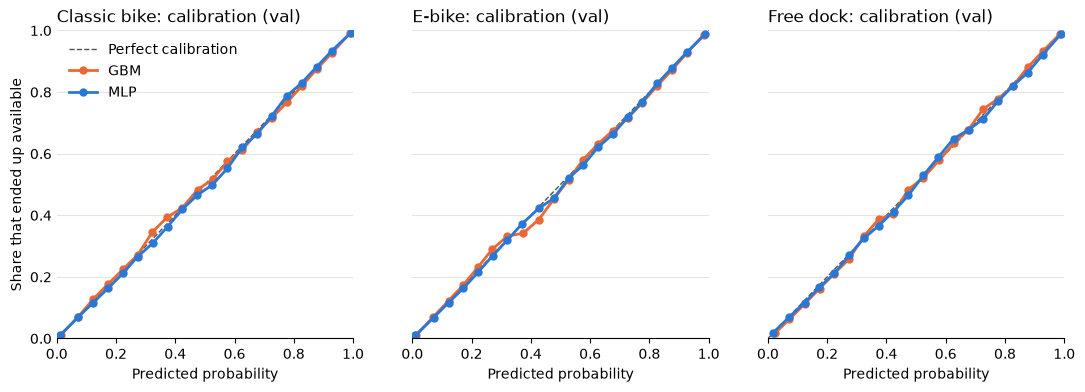

In [15]:
bins = np.linspace(0, 1, 21)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for j, (ax, k) in enumerate(zip(axes, LABELS)):
    keep = masked("val", j)
    y = data["val"]["Y"][keep, j]
    ax.plot([0, 1], [0, 1], color=REFERENCE, linestyle="--", linewidth=1, label="Perfect calibration")
    for name in ["GBM", "MLP"]:
        p = preds["val"][name][keep, j]
        which = np.clip(np.digitize(p, bins) - 1, 0, len(bins) - 2)
        cal = pd.DataFrame({"bin": which, "p": p, "y": y}).groupby("bin").agg(
            p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
        cal = cal[cal["n"] >= 200]
        ax.plot(cal["p"], cal["y"], color=COLORS[name], linewidth=2, marker="o", markersize=5, label=name)
    ax.set_title(f"{TITLE[k]}: calibration (val)", loc="left")
    ax.set_xlabel("Predicted probability")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    tidy(ax)
axes[0].set_ylabel("Share that ended up available")
axes[0].legend(frameon=False, loc="upper left")
plt.show()

### Whole system

What a rider would experience over every row in the table: the rule answers labels whose count now is above 2, and the model answers the rest. The app is scored on the same rows.

The table only holds anchors where at least one count was `<= 2`. Busy stations with plenty of everything are left out, and the rule is almost always right there, so these numbers understate how often the app is already right.

In [16]:
def system_table(split: str) -> pd.DataFrame:
    Y, M = data[split]["Y"], data[split]["M"]
    rows = []
    for j, k in enumerate(LABELS):
        r = {"label": k, "rows": len(Y), "share answered by model": float(M[:, j].mean())}
        r["Brier App"] = brier(Y[:, j], preds[split]["App"][:, j])
        for name in ["Lookup", "GBM", "MLP"]:
            p = np.where(M[:, j] == 1, preds[split][name][:, j], 1.0)
            r[f"Brier rule + {name}"] = brier(Y[:, j], p)
        rows.append(r)
    return pd.DataFrame(rows).set_index("label")


display(system_table("val").round(4))

,rows,share answered by model,Brier App,Brier rule + Lookup,Brier rule + GBM,Brier rule + MLP
label,,,,,,
classic,2083617,0.5126,0.0264,0.0238,0.0212,0.0210
ebike,2083617,0.9261,0.0426,0.0389,0.0356,0.0352
dock,2083617,0.1371,0.0124,0.0107,0.0098,0.0097


## 9. Test results

Runs only with `RUN_TEST = True`. Score the test split once, after every choice has been made on validation. If you change the model after seeing these numbers, the test split is no longer a fair test.

In [21]:
test_results = None
if RUN_TEST:
    test_t = to_tensors("test", torch.device("cpu"))
    preds["test"]["MLP"] = torch.sigmoid(predict_logits(model, test_t["X"], test_t["S"])).cpu().numpy()
    test_results = results_table("test")
    display(test_results.round(4))
    display(test_results["Brier"].unstack("model")[MODELS].round(4).rename_axis("Test Brier"))
    display(breakdown("test", group_count_now, "count now").round(4))
    display(system_table("test").round(4))
else:
    print("RUN_TEST is False, so the test split was not scored.")

rows  share available   Brier  log loss     AUC  Brier skill vs app
label   model                                                                         
classic App      894074           0.4591  0.0430       NaN  0.9566              0.0000
        Lookup   894074           0.4591  0.0395    0.1627  0.9734              0.0832
        GBM      894074           0.4591  0.0358    0.1326  0.9877              0.1687
        MLP      894074           0.4591  0.0355    0.1310  0.9881              0.1746
ebike   App     1609180           0.3260  0.0404       NaN  0.9539              0.0000
        Lookup  1609180           0.3260  0.0375    0.1573  0.9683              0.0726
        GBM     1609180           0.3260  0.0348    0.1332  0.9843              0.1382
        MLP     1609180           0.3260  0.0345    0.1313  0.9851              0.1447
dock    App      252537           0.6191  0.0774       NaN  0.9191              0.0000
        Lookup   252537           0.6191  0.0674    0.2472  0.9512              0.1296
        GBM      252537           0.6191  0.0614    0.2127  0.9698              0.2064
        MLP      252537           0.6191  0.0613    0.2111  0.9701              0.2079

model,App,Lookup,GBM,MLP
Test Brier,,,,
classic,0.0430,0.0395,0.0358,0.0355
dock,0.0774,0.0674,0.0614,0.0613
ebike,0.0404,0.0375,0.0348,0.0345


rows  share available  Brier App  Brier Lookup  Brier GBM  Brier MLP  AUC Lookup  AUC GBM  AUC MLP
label   count now                                                                                                       
classic 0           484300           0.0404     0.0404        0.0379     0.0344     0.0341      0.6495   0.8642   0.8710
        1           250542           0.9342     0.0658        0.0582     0.0525     0.0522      0.6956   0.8567   0.8594
        2           159232           0.9847     0.0153        0.0146     0.0138     0.0137      0.7782   0.9113   0.9149
ebike   0          1085122           0.0302     0.0302        0.0290     0.0273     0.0271      0.6338   0.8424   0.8530
        1           373205           0.9217     0.0783        0.0695     0.0632     0.0627      0.6706   0.8234   0.8282
        2           150853           0.9803     0.0197        0.0190     0.0182     0.0181      0.7180   0.8589   0.8674
dock    0            97330           0.1062     0.1062        0.0912     0.0818     0.0814      0.6547   0.8135   0.8191
        1            84095           0.9128     0.0872        0.0757     0.0697     0.0698      0.6952   0.8228   0.8241
        2            71112           0.9737     0.0263        0.0249     0.0237     0.0237      0.7422   0.8691   0.8714

,rows,share answered by model,Brier App,Brier rule + Lookup,Brier rule + GBM,Brier rule + MLP
label,,,,,,
classic,1747660,0.5116,0.0225,0.0206,0.0187,0.0186
ebike,1747660,0.9208,0.0374,0.0347,0.0322,0.0320
dock,1747660,0.1445,0.0117,0.0103,0.0094,0.0094


## 10. Example query

One anchor at station 7000 from the val split, preferably on a weekday morning showing a single e-bike. `answer_query()` gives the answer the deployed system would show for every arrival time from 2 to 15 minutes. It uses the rule when a count is above 2 and the model otherwise.

The dots are what actually happened at the three horizons sampled for this anchor. The check at the end confirms that `answer_query()` gives the same probabilities as the batch predictions for those rows.

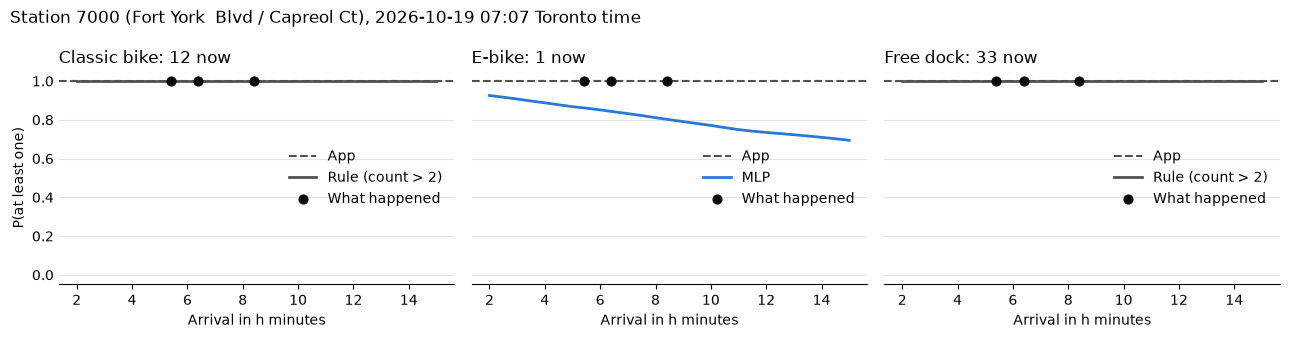

,h,p_classic,answered by classic,p_ebike,answered by ebike,p_dock,answered by dock
0,2.0,1.0,rule,0.925,model,1.0,rule
6,5.0,1.0,rule,0.868,model,1.0,rule
16,10.0,1.0,rule,0.771,model,1.0,rule
26,15.0,1.0,rule,0.694,model,1.0,rule


,t_local,h,classic_now,ebike_now,docks_now,ebike_tm10,ebike_tm30,y_classic,y_ebike,y_dock,m_classic,m_ebike,m_dock
119,2026-10-19T07:07:00-04:00,5.4,12,1,33,1,0,1,1,1,0,1,0
120,2026-10-19T07:07:00-04:00,6.4,12,1,33,1,0,1,1,1,0,1,0
121,2026-10-19T07:07:00-04:00,8.4,12,1,33,1,0,1,1,1,0,1,0


answer_query matches the batch predictions.


In [18]:
def answer_query(row: pd.Series, h_values) -> pd.DataFrame:
    """The deployed answer for one station at one time, for several arrival times h (minutes)."""
    q = pd.DataFrame({c: np.repeat(row[c], len(h_values)) for c in INPUT_COLUMNS + [EMBED_COLUMN]})
    q["h"] = np.asarray(h_values, dtype=np.float32)
    X = torch.from_numpy(make_matrix(q, stats))
    S = torch.from_numpy(station_index(q, train_stations))
    p = torch.sigmoid(predict_logits(model, X, S)).cpu().numpy()
    out = pd.DataFrame({"h": q["h"]})
    for j, k in enumerate(LABELS):
        by_rule = row[NOW_COL[k]] > LOW_COUNT_K
        out[f"p_{k}"] = 1.0 if by_rule else p[:, j]
        out[f"answered by {k}"] = "rule" if by_rule else "model"
    return out


val_frame = frames["val"]
candidates = val_frame[val_frame["station_id"] == EXAMPLE_STATION_ID]
assert len(candidates), f"station {EXAMPLE_STATION_ID} has no val rows, pick another EXAMPLE_STATION_ID"
local_hour = candidates["t_local"].str.slice(11, 13).astype(int)
for rule in [(candidates["ebike_now"] == 1) & (candidates["is_weekend"] == 0) & local_hour.between(7, 9),
             candidates["m_ebike"] == 1,
             candidates["station_id"] == EXAMPLE_STATION_ID]:
    if rule.any():
        example = candidates[rule].iloc[0]
        break

answer = answer_query(example, np.arange(2, 15.5, 0.5))
same_anchor = val_frame[(val_frame["station_id"] == example["station_id"]) & (val_frame["t"] == example["t"])]
name = stations.set_index("station_id").loc[example["station_id"], "name"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for j, (ax, k) in enumerate(zip(axes, LABELS)):
    by_rule = answer[f"answered by {k}"].iloc[0] == "rule"
    ax.axhline(float(example[NOW_COL[k]] >= 1), color=REFERENCE, linestyle="--", linewidth=1.5, label="App")
    ax.plot(answer["h"], answer[f"p_{k}"], color=REFERENCE if by_rule else COLORS["MLP"], linewidth=2,
            label=f"Rule (count > {LOW_COUNT_K})" if by_rule else "MLP")
    ax.scatter(same_anchor["h"], same_anchor[f"y_{k}"], color=INK, s=40, zorder=3, label="What happened")
    ax.set_title(f"{TITLE[k]}: {example[NOW_COL[k]]} now", loc="left")
    ax.set_xlabel("Arrival in h minutes")
    ax.set_ylim(-0.05, 1.05)
    tidy(ax)
    ax.legend(frameon=False, loc="center right")
axes[0].set_ylabel("P(at least one)")
fig.suptitle(f"Station {example['station_id']} ({name}), {example['t_local'][:16].replace('T', ' ')} Toronto time",
             x=0.01, ha="left")
plt.tight_layout()
plt.show()

display(answer[answer["h"].isin([2, 5, 10, 15])].round(3))
display(same_anchor[["t_local", "h", "classic_now", "ebike_now", "docks_now", "ebike_tm10", "ebike_tm30",
                     "y_classic", "y_ebike", "y_dock", "m_classic", "m_ebike", "m_dock"]])

# The single-query path must agree with the batch predictions
check = answer_query(example, same_anchor["h"].to_numpy())
for j, k in enumerate(LABELS):
    if check[f"answered by {k}"].iloc[0] == "model":
        assert np.allclose(check[f"p_{k}"], preds["val"]["MLP"][same_anchor.index, j], atol=1e-5)
print("answer_query matches the batch predictions.")

## 11. Save

- `models/availability_mlp.pt`: the weights, plus everything needed to rebuild the inputs (feature names, train statistics, the stations seen in training, settings). Load it with `torch.load(path)`.
- `models/metrics.json`: the val results (and the test results if `RUN_TEST`), the best epoch and the training history.
- `models/history.csv`: one row per epoch.
- `models/val_predictions.parquet`: for each val row, the labels, masks and every model's probabilities. Use it for later analysis (for example minutes saved for riders). `test_predictions.parquet` is written only if `RUN_TEST`.

The last check reloads the checkpoint into a fresh model and confirms that it gives the same val predictions.

In [22]:
CHECKPOINT_PATH = MODEL_DIR / "availability_mlp.pt"
config = {
    "EMBED_DIM": EMBED_DIM, "HIDDEN": HIDDEN, "DROPOUT": DROPOUT, "STATION_DROPOUT": STATION_DROPOUT,
    "BATCH_SIZE": BATCH_SIZE, "EPOCHS": EPOCHS, "LR": LR, "WEIGHT_DECAY": WEIGHT_DECAY, "PATIENCE": PATIENCE,
    "LOW_COUNT_K": LOW_COUNT_K, "RANDOM_SEED": RANDOM_SEED, "table_rows": N_ROWS,
}
torch.save({
    "state_dict": model.state_dict(),
    "model_args": {"n_features": len(FEATURE_NAMES), "n_stations": N_STATIONS,
                   "embed_dim": EMBED_DIM, "hidden": HIDDEN, "dropout": DROPOUT},
    "feature_names": FEATURE_NAMES,
    "feature_stats": stats,
    "input_columns": INPUT_COLUMNS,
    "train_stations": [int(s) for s in train_stations],
    "unknown_station": UNKNOWN_STATION,
    "labels": LABELS,
    "best_epoch": best_epoch,
    "config": config,
}, CHECKPOINT_PATH)


def records(table: pd.DataFrame | None) -> list | None:
    if table is None:
        return None
    return json.loads(table.reset_index().to_json(orient="records"))


(MODEL_DIR / "metrics.json").write_text(json.dumps({
    "val": records(val_results),
    "val_system": records(system_table("val")),
    "test": records(test_results),
    "best_epoch": best_epoch,
    "config": config,
    "history": records(history_df),
}, indent=2))
history_df.to_csv(MODEL_DIR / "history.csv", index=False)


def predictions_frame(split: str) -> pd.DataFrame:
    out = frames[split][["station_id", "station_idx", "t", "h"]].copy()
    for j, k in enumerate(LABELS):
        out[f"y_{k}"] = data[split]["Y"][:, j].astype("int8")
        out[f"m_{k}"] = data[split]["M"][:, j].astype("int8")
        for name in MODELS:
            out[f"p_{name.lower()}_{k}"] = preds[split][name][:, j]
    return out


predictions_frame("val").to_parquet(MODEL_DIR / "val_predictions.parquet", index=False)
if RUN_TEST:
    predictions_frame("test").to_parquet(MODEL_DIR / "test_predictions.parquet", index=False)

# Reload into a fresh model and compare
saved = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
reloaded = AvailabilityMLP(**saved["model_args"]).to(DEVICE)
reloaded.load_state_dict(saved["state_dict"])
p_reloaded = torch.sigmoid(predict_logits(reloaded, tensors["val"]["X"], tensors["val"]["S"])).cpu().numpy()
assert np.allclose(p_reloaded, preds["val"]["MLP"], atol=1e-6), "reloaded model gives different predictions"

for path in sorted(MODEL_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")
print("Checkpoint reloads and reproduces the val predictions.")

availability_mlp.pt: 0.5 MB
history.csv: 0.0 MB
metrics.json: 0.0 MB
test_predictions.parquet: 43.8 MB
val_predictions.parquet: 51.5 MB
Checkpoint reloads and reproduces the val predictions.
